<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Neural_networks/credit_default_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Project: Predict Credit Card Defaults

**Goal:** a bank has data on 30,000 credit card clients in Taiwan: their credit limit, age, education, six months of repayment history, bill amounts and payments. We want to predict who will **fail to pay their next month's bill** (a "default"). This is a real, imbalanced and slightly messy business problem.

**What is a neural network?** A **neuron** takes numbers in, multiplies each by a **weight**, adds them up with a **bias**, and passes the result through an **activation function** (a small non-linear squash). A **neural network** stacks many neurons into **layers**. Training means nudging all the weights, over and over, to make the prediction error smaller (**gradient descent**, with the gradients computed by **backpropagation**). Here we use the classic **Multi-Layer Perceptron (MLP)**: inputs, one or more hidden layers, and an output.

**What you will learn**

- How a neural network works, by building a tiny one **from scratch** with NumPy.
- Why neural networks **need scaled inputs**, and how to read the **training curves**.
- The main knobs: **layers and neurons**, **regularization** (`alpha`), and **early stopping**.
- Why results change with the **random seed**, and how to measure that.
- An honest comparison: neural network vs logistic regression vs gradient boosting on **table-style** data.
- How to handle an **imbalanced** target with a custom decision threshold.

**Dataset:** the "Default of Credit Card Clients" data from the UCI Machine Learning Repository (30,000 clients, 23 feature columns, and the target `default.payment.next.month`). It is loaded from a URL below, so you do not need to upload anything.

**Steps:** 1) Load, 2) Explore, 3) Prepare, 4) A neural network from scratch, 5) Baselines, 6) Scaling matters, 7) Training curves, 8) Tune the architecture, 9) Seeds, 10) Threshold, 11) Final test, 12) What matters most?, 13) Optional: Keras, 14) Predict a client.

Run the cells from top to bottom (Shift + Enter).

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

url = 'https://huggingface.co/datasets/scikit-learn/credit-card-clients/raw/main/UCI_Credit_Card.csv'
df = pd.read_csv(url)

# the target column is the one that starts with "default" (usually 'default.payment.next.month')
target = [c for c in df.columns if c.lower().startswith('default')][0]
print('Rows and columns:', df.shape)
print('Target column:', target)
df.head()

Rows and columns: (30000, 25)
Target column: default.payment.next.month


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


*If this link ever stops working, search for "Default of Credit Card Clients" on the UCI repository or Kaggle, download the CSV (`UCI_Credit_Card.csv`), upload it to Colab and use `pd.read_csv('UCI_Credit_Card.csv')`.*

Each row is a client. The main columns are:
- `LIMIT_BAL`: the credit limit (in Taiwan dollars). `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: demographics.
- `PAY_0` to `PAY_6`: repayment status for the last six months (-1 or lower means paid on time, 1 or more means that many months late).
- `BILL_AMT1` to `BILL_AMT6`: the bill amounts. `PAY_AMT1` to `PAY_AMT6`: the payments made.
- `default.payment.next.month`: **1 = the client defaulted**, 0 = paid.

## Step 2: Explore the data

Missing values: 0
Duplicated rows (ignoring ID): 35

Defaults vs non-defaults:
default.payment.next.month
0    23364
1     6636
Default rate: 22.1%

SEX -> {1: 11888, 2: 18112}
EDUCATION -> {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE -> {0: 54, 1: 13659, 2: 15964, 3: 323}

Repayment status columns: ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']


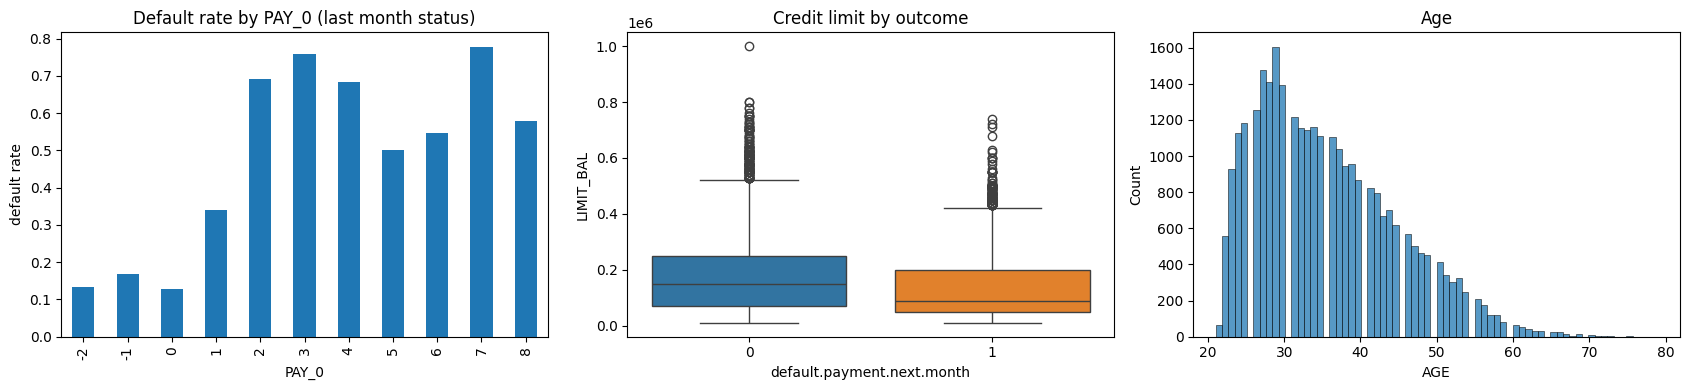

In [2]:
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicated rows (ignoring ID):', int(df.drop(columns=['ID'], errors='ignore').duplicated().sum()))
print()
print('Defaults vs non-defaults:')
print(df[target].value_counts().to_string())
print('Default rate: {:.1%}'.format(df[target].mean()))
print()
for c in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(c, '->', df[c].value_counts().sort_index().to_dict())

pay_cols = [c for c in df.columns if c.startswith('PAY_') and not c.startswith('PAY_AMT')]
print()
print('Repayment status columns:', pay_cols)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
(df.groupby(pay_cols[0])[target].mean()).plot.bar(ax=axes[0])
axes[0].set_title(f'Default rate by {pay_cols[0]} (last month status)')
axes[0].set_ylabel('default rate')
sns.boxplot(data=df, x=target, y='LIMIT_BAL', hue=target, legend=False, ax=axes[1])
axes[1].set_title('Credit limit by outcome')
sns.histplot(df['AGE'], ax=axes[2])
axes[2].set_title('Age')
plt.tight_layout()
plt.show()

**What to notice:**
- Only about **one client in five defaults**, so the classes are **imbalanced**: always predicting "no default" would be right about 78% of the time while catching nobody. We will look at ROC-AUC, precision and recall, not just accuracy.
- `EDUCATION` and `MARRIAGE` contain some **undocumented codes** (such as 0, 5, 6). We will clean them in the next step.
- The most recent repayment status (the first `PAY_` column) is a **very strong signal**: clients who were already 2 or more months late have a much higher default rate.

## Step 3: Prepare the data

1. Drop the `ID` column (it carries no information).
2. Merge the undocumented codes: `EDUCATION` 0, 5 and 6 become 4 ("other"); `MARRIAGE` 0 becomes 3 ("other").
3. Split into **train (75%)** and **test (25%)**, stratified, so both keep the same default rate.
4. In a **pipeline**: one-hot encode the three categorical columns (`SEX`, `EDUCATION`, `MARRIAGE`) and **standardize** all the other columns (mean 0, spread 1). Neural networks are very sensitive to the scale of their inputs, as we will prove in Step 6.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = df.drop(columns=['ID'], errors='ignore')
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

y = df[target].astype(int)
X = df.drop(columns=[target])

cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Training clients:', len(X_train), '| Test clients:', len(X_test))
print('Default rate in training: {:.1%} | in test: {:.1%}'.format(y_train.mean(), y_test.mean()))


def make_prep():
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
                              ('num', StandardScaler(), num_cols)], sparse_threshold=0)


prep_check = make_prep().fit(X_train)
print('Number of input columns after encoding:', prep_check.transform(X_train.head(3)).shape[1])

Training clients: 22500 | Test clients: 7500
Default rate in training: 22.1% | in test: 22.1%
Number of input columns after encoding: 29


## Step 4: A neural network from scratch

Before using a library, let us build a **tiny network** ourselves. We use a toy problem where the two classes are two interleaving half-moons. A straight line cannot separate them, so a model needs a **curved boundary**.

Our network has 2 inputs, 8 hidden neurons (with the `tanh` activation) and 1 output (with the `sigmoid`, giving a probability). Training repeats four steps:

1. **Forward pass:** compute the predictions.
2. **Loss:** measure the error (binary cross-entropy).
3. **Backward pass (backpropagation):** compute how each weight should change to reduce the loss.
4. **Update:** move every weight a small step in that direction (**gradient descent**).

Test accuracy, our network from scratch : 0.947
Test accuracy, scikit-learn MLP         : 0.94
Test accuracy, logistic regression      : 0.84 (a straight line)


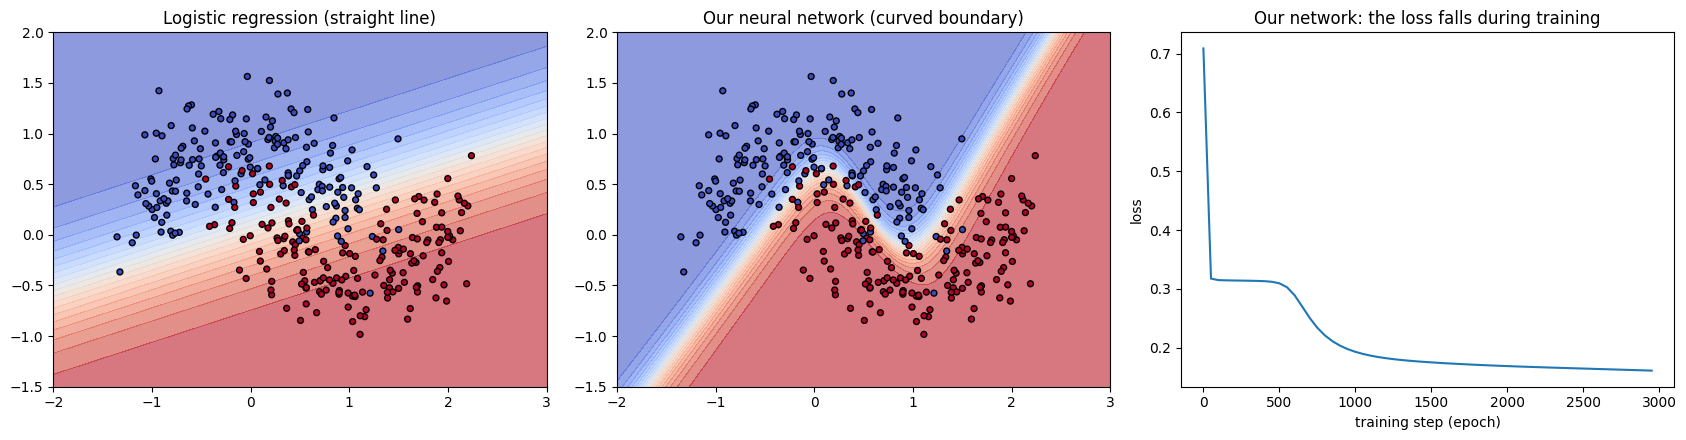

In [4]:
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

Xm, ym = make_moons(n_samples=500, noise=0.25, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0, stratify=ym)

rng = np.random.default_rng(0)
H = 8
W1 = rng.normal(0, 0.5, (2, H)); b1 = np.zeros(H)          # input -> hidden weights
W2 = rng.normal(0, 0.5, (H, 1)); b2 = np.zeros(1)          # hidden -> output weights


def forward(X):
    a1 = np.tanh(X @ W1 + b1)                              # hidden layer
    p = 1 / (1 + np.exp(-(a1 @ W2 + b2)))                  # output probability (sigmoid)
    return a1, p.ravel()


lr = 0.5
losses = []
n = len(Xm_tr)
for epoch in range(3000):
    a1, p = forward(Xm_tr)                                              # 1. forward pass
    loss = -np.mean(ym_tr * np.log(p + 1e-9) + (1 - ym_tr) * np.log(1 - p + 1e-9))   # 2. loss
    dz2 = (p - ym_tr).reshape(-1, 1) / n                                # 3. backward pass
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0)
    dz1 = (dz2 @ W2.T) * (1 - a1 ** 2)
    dW1 = Xm_tr.T @ dz1
    db1 = dz1.sum(axis=0)
    W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2     # 4. update the weights
    if epoch % 50 == 0:
        losses.append(loss)

my_acc = ((forward(Xm_te)[1] > 0.5) == ym_te).mean()
lr_model = LogisticRegression().fit(Xm_tr, ym_tr)
# for a tiny data set, the 'lbfgs' solver is the right choice (the default 'adam' needs many more updates to get going)
sk_mlp = MLPClassifier(hidden_layer_sizes=(8,), activation='tanh', solver='lbfgs', max_iter=3000, random_state=0).fit(Xm_tr, ym_tr)

print('Test accuracy, our network from scratch :', round(my_acc, 3))
print('Test accuracy, scikit-learn MLP         :', round(sk_mlp.score(Xm_te, ym_te), 3))
print('Test accuracy, logistic regression      :', round(lr_model.score(Xm_te, ym_te), 3), '(a straight line)')

# draw the decision boundaries
gx, gy = np.meshgrid(np.linspace(-2, 3, 250), np.linspace(-1.5, 2, 250))
grid = np.c_[gx.ravel(), gy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (title, prob) in zip(axes[:2], [('Logistic regression (straight line)', lr_model.predict_proba(grid)[:, 1]),
                                         ('Our neural network (curved boundary)', forward(grid)[1])]):
    ax.contourf(gx, gy, prob.reshape(gx.shape), levels=20, cmap='coolwarm', alpha=0.6)
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap='coolwarm', edgecolor='k', s=18)
    ax.set_title(title)
axes[2].plot(np.arange(len(losses)) * 50, losses)
axes[2].set_title('Our network: the loss falls during training')
axes[2].set_xlabel('training step (epoch)')
axes[2].set_ylabel('loss')
plt.tight_layout()
plt.show()

**What to notice:** the straight line of logistic regression cuts through both moons, while our little network **bends its boundary** around them and reaches a clearly higher accuracy. Our from-scratch network and scikit-learn's MLP end up in the same range (about 90 to 95% in a real run, against about 84% for the straight line); the exact numbers differ a little because the starting weights are random and the test set is small. (We told scikit-learn to use the `lbfgs` solver, which suits tiny data sets. Its default solver `adam` is built for bigger data and barely gets going on 350 points.) The right-hand plot shows the loss falling as the weights are adjusted. That is all "learning" is: many tiny weight updates that lower the error. A bigger network just has more weights and more layers.

## Step 5: Baselines on the real data

Before training a neural network on the credit data, we measure simpler models on the **training set** with 3-fold cross-validation: a lazy baseline, logistic regression and gradient boosting (the strongest all-rounder for tabular data). We use **ROC-AUC** (the chance that a random defaulter gets a higher score than a random non-defaulter; 0.5 is guessing, 1.0 is perfect).

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

baselines = {
    'Baseline (always "no default")': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(make_prep(), LogisticRegression(max_iter=2000)),
    'Gradient boosting': HistGradientBoostingClassifier(random_state=42),
}

rows = []
for name, m in baselines.items():
    r = cross_validate(m, X_train, y_train, cv=cv3, scoring=['accuracy', 'roc_auc'], n_jobs=-1)
    rows.append({'model': name, 'accuracy': r['test_accuracy'].mean(), 'ROC-AUC': r['test_roc_auc'].mean()})
cv_table = pd.DataFrame(rows)
print(cv_table.round(3).to_string(index=False))

                         model  accuracy  ROC-AUC
Baseline (always "no default")     0.779    0.500
           Logistic regression     0.811    0.726
             Gradient boosting     0.822    0.778


**What to notice:** the lazy baseline already reaches a decent accuracy (about 78%) but a ROC-AUC of 0.5. A realistic target for this data is a ROC-AUC somewhere around 0.72 to 0.80: this problem has a lot of **inherent randomness** (people's finances change), so no model gets close to perfect. Keep these numbers in mind when we evaluate the neural network.

## Step 6: Scaling matters for neural networks

We train the same small MLP twice: once on the **raw numbers** (credit limits in the hundreds of thousands next to repayment codes of -1 or 2) and once on the **standardized** data. We use `early_stopping=True`, so the network keeps 15% of the training data aside and stops when the validation score stops improving.

In [6]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning


def small_mlp(**kw):
    return MLPClassifier(hidden_layer_sizes=(32,), early_stopping=True, validation_fraction=0.15,
                         n_iter_no_change=10, max_iter=300, random_state=42, **kw)


raw_net = make_pipeline(FunctionTransformer(), small_mlp())          # FunctionTransformer() passes the numbers through unchanged
scaled_net = make_pipeline(make_prep(), small_mlp())

rows = []
for name, net in [('MLP on RAW numbers', raw_net), ('MLP on SCALED numbers', scaled_net)]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        net.fit(X_train, y_train)
    mlp = net[-1]
    rows.append({'model': name, 'rounds trained': mlp.n_iter_,
                 'train ROC-AUC': roc_auc_score(y_train, net.predict_proba(X_train)[:, 1]),
                 'test ROC-AUC': roc_auc_score(y_test, net.predict_proba(X_test)[:, 1])})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                model  rounds trained  train ROC-AUC  test ROC-AUC
   MLP on RAW numbers              37          0.660         0.632
MLP on SCALED numbers              27          0.779         0.765


**How to read this:** compare the **test ROC-AUC** of the two rows. Without scaling, the network struggles: the huge numbers (like `BILL_AMT` or `LIMIT_BAL`) create enormous weight updates for some inputs and tiny ones for others, so training is slow, unstable or stuck. Standardizing puts all inputs on a similar footing. **Always scale the inputs of a neural network.**

## Step 7: Training curves

We train the scaled network and look at how it learns, round by round (an **epoch** is one pass through the training data). Two curves matter:

- The **training loss** (the error on the data the network learns from).
- The **validation score** (accuracy on the 15% that the network does not learn from).

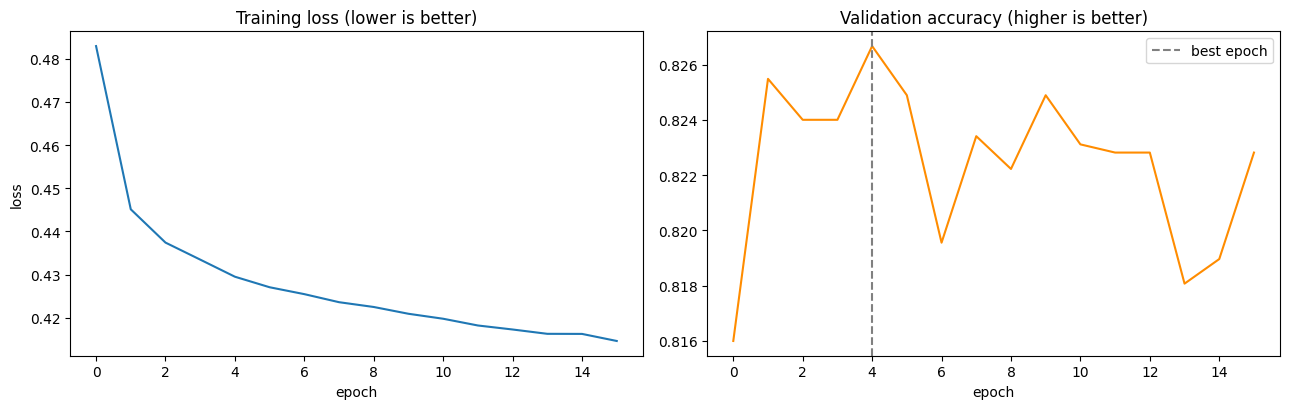

Epochs trained: 16 | best validation accuracy: 0.827


In [7]:
net = make_pipeline(make_prep(), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                validation_fraction=0.15, n_iter_no_change=10,
                                                max_iter=300, random_state=42))
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    net.fit(X_train, y_train)
mlp = net[-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(mlp.loss_curve_)
axes[0].set_title('Training loss (lower is better)')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[1].plot(mlp.validation_scores_, color='darkorange')
axes[1].axvline(int(np.argmax(mlp.validation_scores_)), color='gray', linestyle='--', label='best epoch')
axes[1].set_title('Validation accuracy (higher is better)')
axes[1].set_xlabel('epoch')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Epochs trained:', mlp.n_iter_, '| best validation accuracy: {:.3f}'.format(max(mlp.validation_scores_)))

**How to read this:** the training loss usually keeps going down, because the network keeps memorizing the training data. The validation accuracy rises, then **flattens or even drops**: after that point the network is **overfitting** (learning noise). Early stopping ends training a few epochs after the validation score stops improving, which saves time and protects against overfitting.

## Step 8: Tune the architecture and the regularization

Two important choices:

- **The architecture:** how many hidden layers and neurons. More capacity means the network can learn more complex patterns, but it overfits more easily and trains slower.
- **`alpha`:** the strength of the **L2 regularization**, a penalty that keeps the weights small. A larger `alpha` gives a simpler, smoother model.

We test a few combinations with 3-fold cross-validation (this step can take a few minutes).

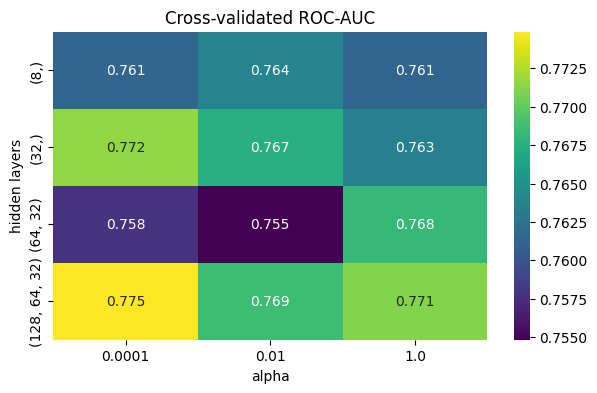

Best settings: {'alpha': 0.0001, 'hidden_layer_sizes': (128, 64, 32)}
Best cross-validated ROC-AUC: 0.7749


In [8]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(make_prep(), MLPClassifier(early_stopping=True, validation_fraction=0.15,
                                                n_iter_no_change=10, max_iter=300, random_state=42))
param_grid = {
    'mlpclassifier__hidden_layer_sizes': [(8,), (32,), (64, 32), (128, 64, 32)],
    'mlpclassifier__alpha': [0.0001, 0.01, 1.0],
}
grid = GridSearchCV(pipe, param_grid, cv=cv3, scoring='roc_auc', n_jobs=-1)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    grid.fit(X_train, y_train)

res = pd.DataFrame(grid.cv_results_)
heat = res.assign(arch=res['param_mlpclassifier__hidden_layer_sizes'].astype(str),
                  alpha=res['param_mlpclassifier__alpha']).pivot(index='arch', columns='alpha', values='mean_test_score')
heat = heat.loc[[str(h) for h in param_grid['mlpclassifier__hidden_layer_sizes']]].astype(float)

plt.figure(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis')
plt.title('Cross-validated ROC-AUC')
plt.ylabel('hidden layers')
plt.show()

print('Best settings:', {k.replace('mlpclassifier__', ''): v for k, v in grid.best_params_.items()})
print('Best cross-validated ROC-AUC:', round(grid.best_score_, 4))
best_params = {k.replace('mlpclassifier__', ''): v for k, v in grid.best_params_.items()}

**How to read this:** compare the cells. On tabular data like this the scores are often **very close to each other**: a small network does about as well as a big one, and more regularization can help the bigger ones. If the differences are tiny (a few thousandths), pick the **simplest** network that is near the top. It is faster and more stable.

## Step 9: The random seed matters

A neural network starts from **random weights**, so each run ends in a slightly different place. A single run can be lucky or unlucky. We train the best configuration with 5 different seeds and look at the spread of the test ROC-AUC.

In [9]:
aucs = []
for seed in range(5):
    m = make_pipeline(make_prep(), MLPClassifier(early_stopping=True, validation_fraction=0.15, n_iter_no_change=10,
                                                 max_iter=300, random_state=seed, **best_params))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        m.fit(X_train, y_train)
    aucs.append(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]))

print('Test ROC-AUC with 5 different seeds:', np.round(aucs, 4))
print(f'Mean {np.mean(aucs):.4f} | spread (std) {np.std(aucs):.4f}')

Test ROC-AUC with 5 different seeds: [0.7705 0.7721 0.7606 0.7678 0.7548]
Mean 0.7651 | spread (std) 0.0065


**What to notice:** the AUC changes a little between seeds. When you compare two models, only trust a difference that is **bigger than this seed-to-seed spread**. In your portfolio, report the mean (and the spread) over several seeds, not the luckiest run.

## Step 10: Choose a decision threshold

By default a model says "default" when the predicted probability is above 0.5. With only about 22% defaulters, that cut-off misses many of them. A bank may prefer to catch more defaulters at the price of more false alarms. We pick the threshold that gives the best **F1 score** (a balance of precision and recall), using **cross-validated predictions on the training set** so the test set stays untouched.

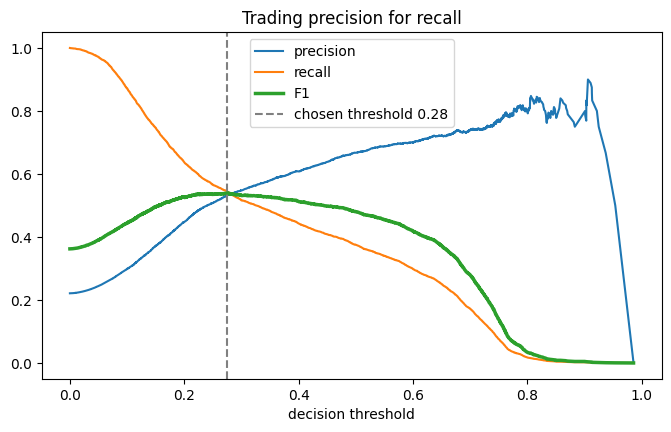

Chosen threshold: 0.275 | cross-validated F1 at this threshold: 0.538


In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

final_net = make_pipeline(make_prep(), MLPClassifier(early_stopping=True, validation_fraction=0.15, n_iter_no_change=10,
                                                     max_iter=300, random_state=42, **best_params))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    cv_proba = cross_val_predict(final_net, X_train, y_train, cv=cv3, method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, cv_proba)
with np.errstate(invalid='ignore', divide='ignore'):
    f1 = np.nan_to_num(2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1]))
best_thr = float(thr[int(np.argmax(f1))])

plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label='precision')
plt.plot(thr, rec[:-1], label='recall')
plt.plot(thr, f1, label='F1', linewidth=2.5)
plt.axvline(best_thr, color='gray', linestyle='--', label=f'chosen threshold {best_thr:.2f}')
plt.xlabel('decision threshold')
plt.title('Trading precision for recall')
plt.legend()
plt.show()
print('Chosen threshold:', round(best_thr, 3), '| cross-validated F1 at this threshold:', round(float(f1.max()), 3))

**How to read this:** raising the threshold makes the model pickier (higher precision, lower recall); lowering it flags more clients (higher recall, lower precision). The best F1 usually sits **below 0.5** for imbalanced data. In a real bank, you would choose the threshold from the **cost** of each type of mistake, not from F1 alone.

## Step 11: Final test

This is the first time the **test set** is used for judging. We fit the final network and compare it with the baselines on the same test clients.

               model  ROC-AUC  average precision  accuracy @0.5
 Logistic regression    0.717              0.503          0.810
   Gradient boosting    0.779              0.554          0.819
Neural network (MLP)    0.769              0.547          0.817

Neural network with the chosen threshold (0.28):
              precision    recall  f1-score   support

  no default      0.872     0.841     0.856      5841
     default      0.502     0.565     0.532      1659

    accuracy                          0.780      7500
   macro avg      0.687     0.703     0.694      7500
weighted avg      0.790     0.780     0.784      7500



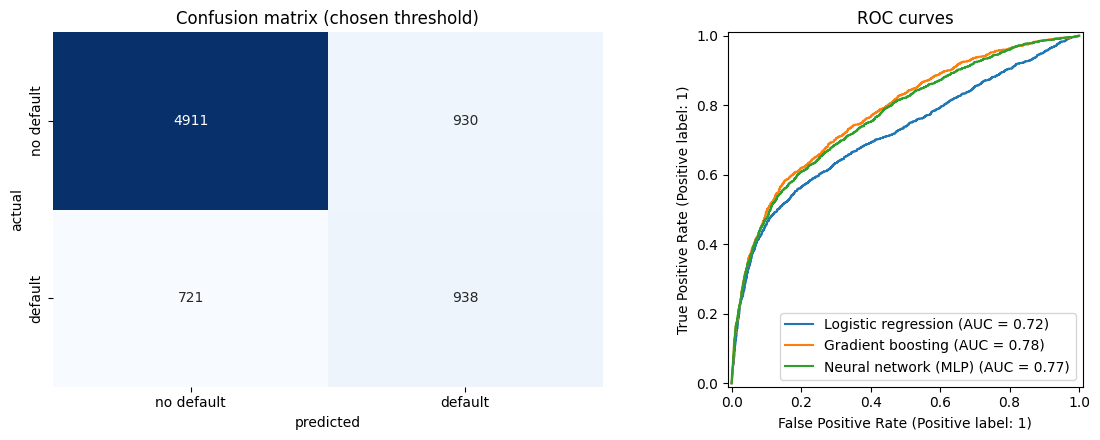

In [11]:
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             RocCurveDisplay, average_precision_score)

models = {
    'Logistic regression': make_pipeline(make_prep(), LogisticRegression(max_iter=2000)),
    'Gradient boosting': HistGradientBoostingClassifier(random_state=42),
    'Neural network (MLP)': final_net,
}
rows, probs = [], {}
for name, m in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    probs[name] = p
    rows.append({'model': name, 'ROC-AUC': roc_auc_score(y_test, p), 'average precision': average_precision_score(y_test, p),
                 'accuracy @0.5': accuracy_score(y_test, (p >= 0.5).astype(int))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

p_nn = probs['Neural network (MLP)']
pred = (p_nn >= best_thr).astype(int)
print()
print(f'Neural network with the chosen threshold ({best_thr:.2f}):')
print(classification_report(y_test, pred, target_names=['no default', 'default'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['no default', 'default'], yticklabels=['no default', 'default'])
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('actual')
axes[0].set_title('Confusion matrix (chosen threshold)')
for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[1].set_title('ROC curves')
plt.tight_layout()
plt.show()

**How to read this:**
- Compare the **ROC-AUC** column. On table-style data like this, a well-tuned neural network usually lands **close to** gradient boosting and logistic regression, and often does **not** beat gradient boosting. Neural networks really shine on **images, text, audio and other unstructured data**; for spreadsheets, tree-based boosting is often just as good or better, and faster to tune.
- In the classification report, look at the **recall for "default"**: the share of true defaulters that the model catches at the chosen threshold, and the **precision** (the share of its alarms that are right). That trade-off is the part a bank cares about.

## Step 12: What matters most to the network?

A neural network is a black box, but we can still ask which columns it depends on. **Permutation importance** shuffles one column at a time in the test set and measures how much the ROC-AUC drops.

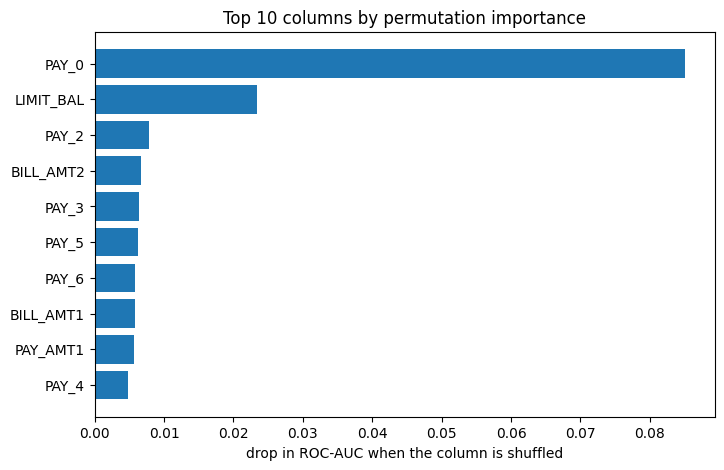

In [12]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(final_net, X_test, y_test, scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({'feature': X_test.columns, 'drop in ROC-AUC': imp.importances_mean}) \
    .sort_values('drop in ROC-AUC', ascending=False).head(10).iloc[::-1]

plt.figure(figsize=(8, 5))
plt.barh(imp_df['feature'], imp_df['drop in ROC-AUC'])
plt.xlabel('drop in ROC-AUC when the column is shuffled')
plt.title('Top 10 columns by permutation importance')
plt.show()

**What to notice:** check whether the **recent repayment status columns** (`PAY_0`, `PAY_2`, ...) are at the top. That matches common sense: someone who is already late on payments is the most likely to default. A model whose important features match what an expert would expect is easier to trust.

## Step 13 (optional): The same network in Keras

In practice many people build neural networks with **Keras** (part of TensorFlow), which is pre-installed in Google Colab. It can also build far larger networks (images, text) and run on a GPU. Here is the same idea: two hidden layers with **dropout** (randomly switching off neurons during training, another regularizer) and early stopping. If TensorFlow is not installed, the cell just tells you how to install it.

Epochs trained: 31
Keras test ROC-AUC       : 0.771
scikit-learn MLP test AUC: 0.7693


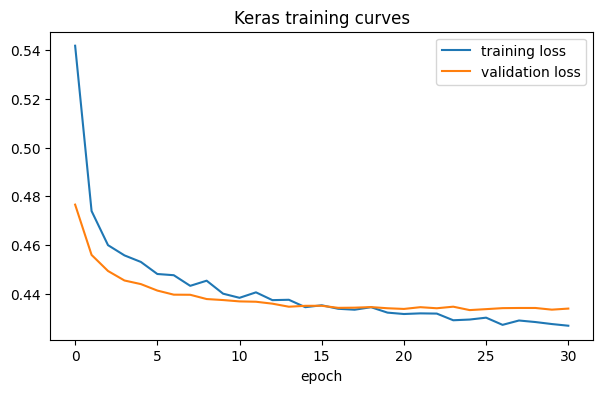

In [13]:
try:
    import tensorflow as tf
    from tensorflow import keras

    tf.keras.utils.set_random_seed(42)
    prep = make_prep().fit(X_train)
    Xtr = prep.transform(X_train).astype('float32')
    Xte = prep.transform(X_test).astype('float32')

    model = keras.Sequential([
        keras.layers.Input(shape=(Xtr.shape[1],)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['AUC'])
    history = model.fit(Xtr, y_train.values, validation_split=0.15, epochs=60, batch_size=256, verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)])

    p_keras = model.predict(Xte, verbose=0).ravel()
    print('Epochs trained:', len(history.history['loss']))
    print('Keras test ROC-AUC       :', round(roc_auc_score(y_test, p_keras), 4))
    print('scikit-learn MLP test AUC:', round(roc_auc_score(y_test, p_nn), 4))

    plt.figure(figsize=(7, 4))
    plt.plot(history.history['loss'], label='training loss')
    plt.plot(history.history['val_loss'], label='validation loss')
    plt.xlabel('epoch')
    plt.legend()
    plt.title('Keras training curves')
    plt.show()
except ImportError:
    print('TensorFlow is not installed here. Run:  pip install tensorflow   (Google Colab already has it)')

**What to notice:** the Keras network should reach a ROC-AUC close to scikit-learn's MLP, since it is the same kind of model. The difference is the tooling: Keras gives you dropout, GPUs, custom layers and callbacks, which you need for deep learning on images and text.

## Step 14: Predict a client

We take one client from the test set, and see how the predicted default probability changes when we make the client late on the last payment.

In [14]:
client = X_test.iloc[[0]].copy()
p0 = final_net.predict_proba(client)[0, 1]

late = client.copy()
late[pay_cols[0]] = 3                       # three months late on the latest payment status
p1 = final_net.predict_proba(late)[0, 1]

print('Client:')
print(client.T.head(8).to_string(header=False))
print()
print(f'Default probability as is           : {p0:.0%}  -> {"DEFAULT" if p0 >= best_thr else "no default"} (threshold {best_thr:.2f})')
print(f'If {pay_cols[0]} were 3 (3 months late) : {p1:.0%}  -> {"DEFAULT" if p1 >= best_thr else "no default"}')
print('Actual outcome of this client:', 'default' if y_test.iloc[0] == 1 else 'no default')

Client:
LIMIT_BAL  50000.0
SEX            1.0
EDUCATION      2.0
MARRIAGE       1.0
AGE           45.0
PAY_0          1.0
PAY_2          2.0
PAY_3          0.0

Default probability as is           : 45%  -> DEFAULT (threshold 0.28)
If PAY_0 were 3 (3 months late) : 66%  -> DEFAULT
Actual outcome of this client: default


**Try it:** change other columns (the credit limit, the age, the payments) and see what moves the probability the most.

*Reminder:* this is a learning project on a data set from 2005. A real credit decision needs legal review, fairness checks and far more care.

## Practice ideas

1. In Step 8, try the `relu` and `tanh` activation functions (`activation=...`) and the `adam` and `sgd` solvers.
2. Try `class_weight`-like effects by oversampling the defaulters (or `sample_weight`) and compare recall.
3. Add the `MLPRegressor` to predict `LIMIT_BAL` from the other columns, and measure it with MAE and R².
4. Build a neural network for the **digits** data (`load_digits`), and compare it with your Naive Bayes project. Images are where neural networks beat the other algorithms the most.
5. In Keras, try different dropout rates, more layers, and the `BatchNormalization` layer.
6. Create new features (for example, the average of the six `PAY_` columns, or the ratio of payments to bills) and see whether they help the network or the gradient boosting model more.